<a href="https://colab.research.google.com/github/sociallyH03ly/Financial-Account-Ownership-Among-Filipino-Adults-Findex-2025-/blob/main/Findex_Philippines_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Findex 2025 – Philippines microdata: Exploratory Data Analysis

By: Michael Angelo S. Manzano

**Data:** `Findex_Microdata_2025_updatePhilippines.csv` (individual-level, survey year 2024) · **Codebook:** *Global Findex 2025 Microdata Codebook*

> **Important:** all population-level statements use the survey weight `wgt`. Confidence intervals use the Kish effective sample size, an approximation (the file has no strata/PSU identifiers, so design effects from clustering are not captured).

## 0. Setup

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

# ---- Where is the data? -------------------------------------------------
# Option A (default): run this cell and use the upload dialog in Colab.
# Option B: set DATA_PATH yourself, e.g. "/content/drive/MyDrive/Findex_Microdata_2025_updatePhilippines.csv"
DATA_PATH = None

def locate_data():
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH
    hits = sorted(glob.glob("*Findex*Philippines*.csv") + glob.glob("/content/*Findex*Philippines*.csv"))
    if hits:
        return hits[0]
    try:
        from google.colab import files           # only exists inside Colab
        print("Please select the Findex Philippines CSV file...")
        up = files.upload()
        return next(iter(up))
    except ImportError:
        raise FileNotFoundError("CSV not found. Set DATA_PATH or place the file next to the notebook.")

path = locate_data()
df_raw = pd.read_csv(path, low_memory=False)
print(f"Loaded: {path}\nRows: {len(df_raw):,}   Columns: {df_raw.shape[1]}")

Please select the Findex Philippines CSV file...


Saving Findex_Microdata_2025_updatePhilippines.csv to Findex_Microdata_2025_updatePhilippines.csv
Loaded: Findex_Microdata_2025_updatePhilippines.csv
Rows: 1,000   Columns: 199


## 1. Structure and integrity

In [2]:
df = df_raw.copy()

# Column blocks, following the codebook sections
DEMO = ["year","economy","economycode","regionwb","pop_adult","wpid_random","wgt","female","age","educ","inc_q","emp_in","urbanicity"]
CONSTRUCTED = ["account_fin","account_mob","account","dig_account","borrowed","saved","receive_wages","receive_transfers",
               "receive_pensions","receive_agriculture","merchantpay_dig","pay_utilities","domestic_remittances","anydigpayment"]
def block_of(c):
    if c in DEMO: return "Demographics / design"
    if c in CONSTRUCTED: return "Constructed financial"
    if c == "internet_use": return "Constructed connectivity"
    if c.startswith("con"): return "Connectivity questionnaire (con*)"
    if c in [f"fin4{i}" for i in (6,7)] or c.startswith(("fin48","fin49","fin50","fin51")): return "ID4D (fin46-fin51)"
    return "Financial questionnaire (fin*/fh*)"
blocks = pd.Series({c: block_of(c) for c in df.columns})

print("Block sizes:"); print(blocks.value_counts().to_string())
print("\nDtypes:"); print(df.dtypes.astype(str).value_counts().to_string())
print("\nNote: codebook names the connectivity indicator `internet`; in this file it is `internet_use`.")
print("Columns in file but not in the codebook's main list: internet_use, year")

display(df[DEMO].head(5))

Block sizes:
Financial questionnaire (fin*/fh*)    103
Connectivity questionnaire (con*)      52
ID4D (fin46-fin51)                     16
Constructed financial                  14
Demographics / design                  13
Constructed connectivity                1

Dtypes:
float64    147
int64       49
object       3

Note: codebook names the connectivity indicator `internet`; in this file it is `internet_use`.
Columns in file but not in the codebook's main list: internet_use, year


,year,economy,economycode,regionwb,pop_adult,wpid_random,wgt,female,age,educ,inc_q,emp_in,urbanicity
0,2024,Philippines,PHL,East Asia & Pacific (excluding high income),82023644,111160291,0.294,1,38,2,3,1,2
1,2024,Philippines,PHL,East Asia & Pacific (excluding high income),82023644,111468701,4.521,2,25,3,4,2,2
2,2024,Philippines,PHL,East Asia & Pacific (excluding high income),82023644,111475292,0.172,1,69,2,3,1,1
3,2024,Philippines,PHL,East Asia & Pacific (excluding high income),82023644,111617499,1.232,2,58,1,1,1,1
4,2024,Philippines,PHL,East Asia & Pacific (excluding high income),82023644,111636072,0.132,2,63,2,4,1,1


In [3]:
print("Unique respondent IDs :", df["wpid_random"].is_unique)
print("Fully duplicated rows  :", df.duplicated().sum())
print("Economies              :", df["economy"].unique().tolist(), "| years:", df["year"].unique().tolist())
print("Regions                :", df["regionwb"].unique().tolist())
print("Adult population (WDI 2023): {:,}".format(int(df["pop_adult"].iloc[0])))
display(df[["age","wgt"]].describe().T)

Unique respondent IDs : True
Fully duplicated rows  : 0
Economies              : ['Philippines'] | years: [2024]
Regions                : ['East Asia & Pacific (excluding high income)']
Adult population (WDI 2023): 82,023,644


,count,mean,std,min,25%,50%,75%,max
age,"1,000.000",41.506,17.423,15.000,27.000,39.000,55.250,89.000
wgt,"1,000.000",1.000,1.153,0.132,0.228,0.554,1.232,4.521


## 2. Missingness: it is mostly *structural*
In Findex, most questions are only asked of a subgroup (e.g. `fin11*` only of adults without a financial-institution account), so blank cells are usually **by design**, not data errors.

In [4]:
nn = df.notna().sum()
miss = pd.DataFrame({"block": blocks, "non_null": nn, "share_asked": nn/len(df)})
miss["status"] = np.select([miss.non_null==0, miss.non_null==len(df)], ["ALL EMPTY","asked of everyone"], "subgroup only")

print(miss["status"].value_counts().to_string())
print("\nBy block:")
display(pd.crosstab(miss["block"], miss["status"]))

empty = miss.index[miss.status=="ALL EMPTY"].tolist()
print(f"\nAll-empty variables ({len(empty)}): {empty}")
print("-> Not asked/collected for the Philippines (e.g. fin13*/fin14* mobile-money detail, fin50/fin51 digital ID). Nothing to analyse there.")

status
subgroup only        126
asked of everyone     53
ALL EMPTY             20

By block:


status,ALL EMPTY,asked of everyone,subgroup only
block,,,
Connectivity questionnaire (con*),1,2,49
Constructed connectivity,0,1,0
Constructed financial,0,14,0
Demographics / design,0,13,0
Financial questionnaire (fin*/fh*),17,22,64
ID4D (fin46-fin51),2,1,13



All-empty variables (20): ['fin13_1', 'fin13a', 'fin13b', 'fin13c', 'fin13d', 'fin13e', 'fin13f', 'fin13f_1', 'fin14a', 'fin14b', 'fin14c', 'fin14d', 'fin14e', 'fin15', 'fin16', 'fin36a', 'fin41a', 'con15', 'fin50', 'fin51']
-> Not asked/collected for the Philippines (e.g. fin13*/fin14* mobile-money detail, fin50/fin51 digital ID). Nothing to analyse there.


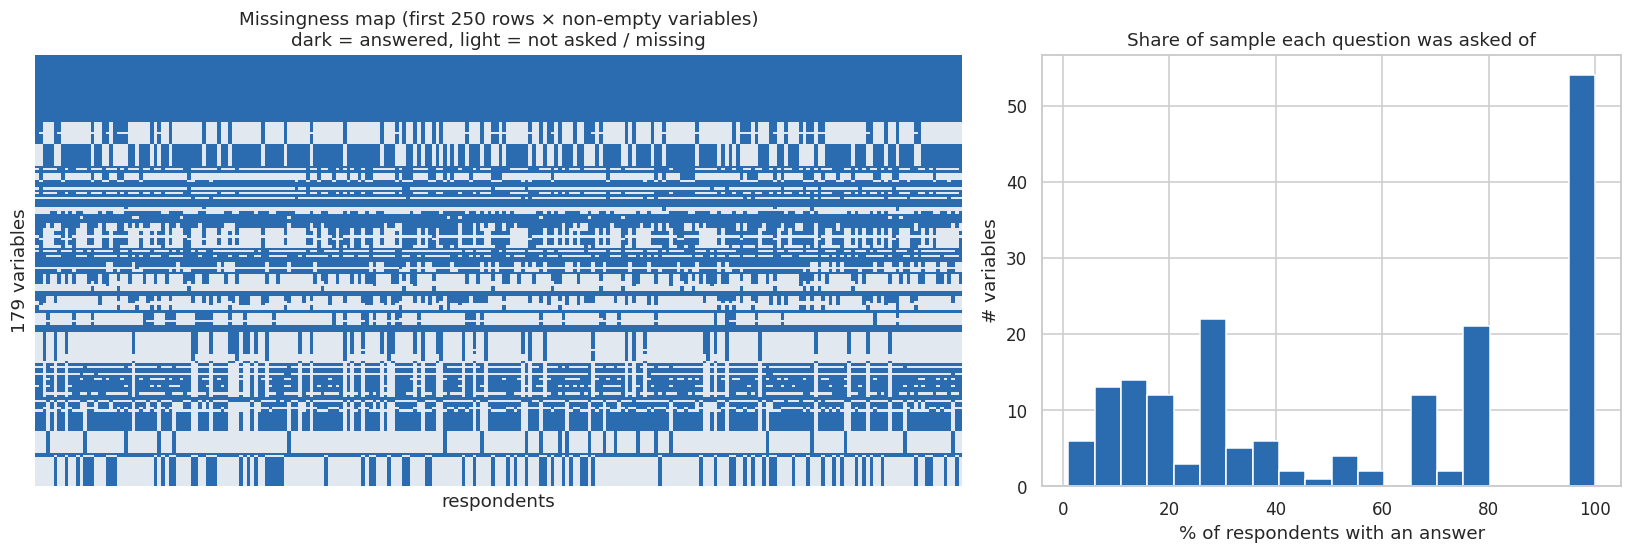

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios":[1.6,1]})
order = [c for c in df.columns if c not in empty]
sns.heatmap(df.loc[:, order].isna().iloc[:250].T, cmap=["#2b6cb0","#e2e8f0"], cbar=False, yticklabels=False, xticklabels=False, ax=axes[0])
axes[0].set_title("Missingness map (first 250 rows × non-empty variables)\ndark = answered, light = not asked / missing")
axes[0].set_xlabel("respondents"); axes[0].set_ylabel(f"{len(order)} variables")

(miss[miss.status!="ALL EMPTY"]["share_asked"]*100).plot.hist(bins=20, ax=axes[1], color="#2b6cb0", edgecolor="white")
axes[1].set_title("Share of sample each question was asked of"); axes[1].set_xlabel("% of respondents with an answer"); axes[1].set_ylabel("# variables")
plt.tight_layout(); plt.show()

## 3. Recoding: "don't know" / "refused" → missing
The codebook uses different DK/refused codes per variable (3/4, 4/5, 5/6, 7/8, 8/9, 98/99). The map below follows it. Original columns stay in `df_raw`; the cleaned copy is `dc`, and `dk_count` records how many DK/refused answers each respondent gave.

In [6]:
DK_DEFAULT_FIN, DK_DEFAULT_CON = {3,4}, {8,9}
DK_OVERRIDE = {
    "fin5":{5,6}, "fin6":{5,6}, "fin13a":{5,6}, "fin13b":{5,6}, "fin13c":{5,6},
    "fin17d":{4,5}, "fin24":{8,9}, "fin24a":{4,5}, "fin24b":{5,6}, "fin25e3":{4,5}, "fin25e4":{6,7},
    "fin27":{4,5}, "fin36":{4,5}, "fin36a":{4,5}, "fin40":{4,5}, "fin41a":{4,5}, "fin45":{7,8},
    "receive_wages":{5}, "receive_transfers":{5}, "receive_pensions":{5}, "receive_agriculture":{5},
    "pay_utilities":{5}, "domestic_remittances":{4}, "con3":{98,99}, "con32":{98,99},
}
# Multi-category variables (legit codes above 2) - excluded from the "undocumented code" test below
MULTI = set(DK_OVERRIDE) | {"con12","con17","con26","con28","fin11b"}

def dk_set(c):
    if c in DK_OVERRIDE: return DK_OVERRIDE[c]
    if c.startswith("con"): return DK_DEFAULT_CON
    if c.startswith(("fin","fh")): return DK_DEFAULT_FIN
    return set()

dc = df.copy()
dk_log = {}
for c in df.columns:
    s = dk_set(c)
    if s and c not in DEMO and c not in CONSTRUCTED[:6]:
        m = dc[c].isin(s)
        if m.any():
            dk_log[c] = int(m.sum()); dc.loc[m, c] = np.nan
dk_flags = [df_raw[c].isin(dk_set(c)) for c in df_raw.columns if dk_set(c) and c not in DEMO and c not in CONSTRUCTED[:6]]
dc["dk_count"] = pd.concat(dk_flags, axis=1).sum(axis=1).values

dk_tab = pd.Series(dk_log, name="n_DK_or_refused").sort_values(ascending=False)
print(f"{len(dk_tab)} variables contain DK/refused answers; {int(dk_tab.sum())} cells recoded to NaN in total")
display(dk_tab.head(15).to_frame())
print("Respondents with at least one DK/refused:", int((dc.dk_count>0).sum()))

91 variables contain DK/refused answers; 331 cells recoded to NaN in total


,n_DK_or_refused
fin24b,44
fin24,26
fin11_2,22
fin11b,17
fin17d,15
fin5,12
fin48c,12
fin11f,8
fin6,8
fin45,7


Respondents with at least one DK/refused: 163


In [7]:
# Codes that are NOT documented in the codebook for binary yes/no questions
sus = []
for c in df.columns:
    if c in DEMO or c in CONSTRUCTED or c == "internet_use" or c in MULTI: continue
    allowed = {1,2} | dk_set(c)
    bad = sorted(set(df_raw[c].dropna().unique()) - allowed)
    if bad: sus.append((c, [int(b) for b in bad], int(df_raw[c].isin(bad).sum())))
print("Undocumented codes in yes/no variables (variable, codes, n):")
for s in sus: print("  ", s)
print("-> If anything is listed, it is worth confirming with the data provider; here it is treated as missing where it matters.")

Undocumented codes in yes/no variables (variable, codes, n):
   ('con24', [3], 1)
-> If anything is listed, it is worth confirming with the data provider; here it is treated as missing where it matters.


## 4. Labels and analysis-ready variables
Codebook gotcha: **`female` is 1 = female, 2 = male** (not 0/1).

In [8]:
lab = pd.DataFrame(index=dc.index)
lab["gender"]  = dc["female"].map({1:"Female", 2:"Male"})
lab["age_grp"] = pd.cut(dc["age"], [14,24,34,44,54,64,120], labels=["15-24","25-34","35-44","45-54","55-64","65+"])
lab["educ"]    = dc["educ"].map({1:"Primary or less", 2:"Secondary", 3:"Tertiary+"})
lab["income_q"]= dc["inc_q"].map({1:"Q1 (poorest)",2:"Q2",3:"Q3",4:"Q4",5:"Q5 (richest)"})
lab["workforce"]= dc["emp_in"].map({1:"In workforce", 2:"Out of workforce"})
lab["area"]    = dc["urbanicity"].map({1:"Rural", 2:"Urban"})

def yes(col, base=None):
    """1 if answered 'yes' (code 1), 0 if answered otherwise, NaN if not asked or DK/refused."""
    s = dc[col]
    out = pd.Series(np.where(s.isna(), np.nan, (s==1).astype(float)), index=dc.index)
    return out

ind = pd.DataFrame(index=dc.index)
ind["Any account"]              = dc["account"].astype(float)
ind["Financial institution acct"]= dc["account_fin"].astype(float)
ind["Mobile money account"]     = dc["account_mob"].astype(float)
ind["Digitally enabled account"]= dc["dig_account"].astype(float)
ind["Any digital payment"]      = dc["anydigpayment"].astype(float)
ind["Digital merchant payment"] = dc["merchantpay_dig"].astype(float)
ind["Saved (any)"]              = dc["saved"].astype(float)
ind["Borrowed (any)"]           = dc["borrowed"].astype(float)
ind["Owns mobile phone"]        = yes("con1")
ind["Smartphone (of all adults)"]= pd.Series(np.where(dc.con1==1, (dc.con9==1).astype(float), 0.0), index=dc.index)
ind["Used internet (3 months)"] = dc["internet_use"].astype(float)
ind["Has foundational ID"]      = yes("fin46")
ind["Has debit card"]           = yes("fin2")
ind["Received wage into account"]= (dc["receive_wages"]==1).astype(float)
ind["Domestic remittance via account"] = (dc["domestic_remittances"]==1).astype(float)
ind["Experienced natural disaster (3y)"] = yes("fin24c")
print("Analysis variables ready:", list(ind.columns))

Analysis variables ready: ['Any account', 'Financial institution acct', 'Mobile money account', 'Digitally enabled account', 'Any digital payment', 'Digital merchant payment', 'Saved (any)', 'Borrowed (any)', 'Owns mobile phone', 'Smartphone (of all adults)', 'Used internet (3 months)', 'Has foundational ID', 'Has debit card', 'Received wage into account', 'Domestic remittance via account', 'Experienced natural disaster (3y)']


## 5. Sample design: weights and representativeness

Mean weight          : 1.000  (should be ≈ 1)
Min / median / max   : 0.132 / 0.554 / 4.521
Weight CV            : 1.153
Kish effective n     : 429 of 1,000   ->  design effect from weighting ≈ 2.33
Largest weight share : 0.45% of total weight (single respondent)


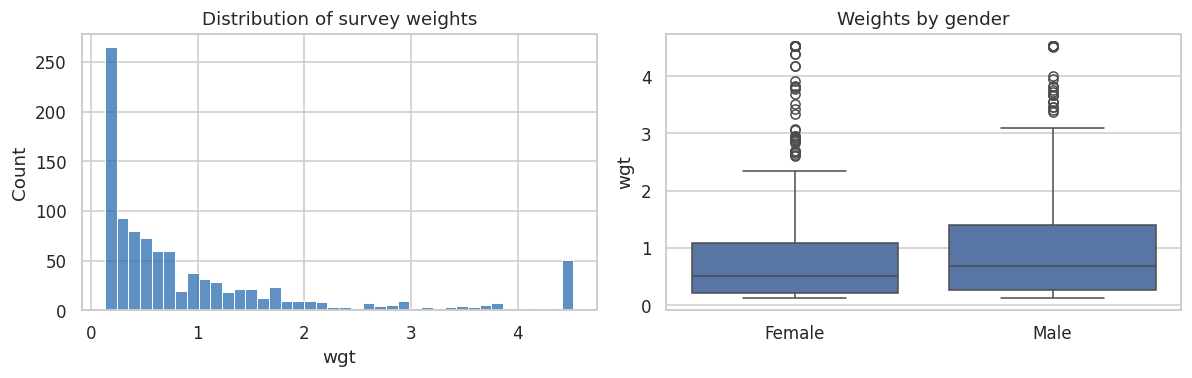

In [9]:
w = dc["wgt"]
neff = w.sum()**2 / (w**2).sum()
print(f"Mean weight          : {w.mean():.3f}  (should be ≈ 1)")
print(f"Min / median / max   : {w.min():.3f} / {w.median():.3f} / {w.max():.3f}")
print(f"Weight CV            : {w.std()/w.mean():.3f}")
print(f"Kish effective n     : {neff:,.0f} of {len(w):,}   ->  design effect from weighting ≈ {len(w)/neff:.2f}")
print(f"Largest weight share : {w.max()/w.sum():.2%} of total weight (single respondent)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(w, bins=40, ax=ax[0], color="#2b6cb0"); ax[0].set_title("Distribution of survey weights"); ax[0].set_xlabel("wgt")
sns.boxplot(x=lab["gender"], y=w, ax=ax[1]); ax[1].set_title("Weights by gender"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

In [10]:
def comp(series):
    u = series.value_counts(normalize=True)
    wt = w.groupby(series).sum() / w.sum()
    out = pd.DataFrame({"unweighted_%": u*100, "weighted_%": wt*100})
    out["diff_pp"] = out["weighted_%"] - out["unweighted_%"]
    return out

rows = []
for g in ["gender","age_grp","educ","income_q","workforce","area"]:
    t = comp(lab[g]); t.index = pd.MultiIndex.from_product([[g], t.index]); rows.append(t)
comp_tab = pd.concat(rows)
display(comp_tab.style.format("{:.1f}").background_gradient(subset=["diff_pp"], cmap="RdBu_r", vmin=-15, vmax=15))

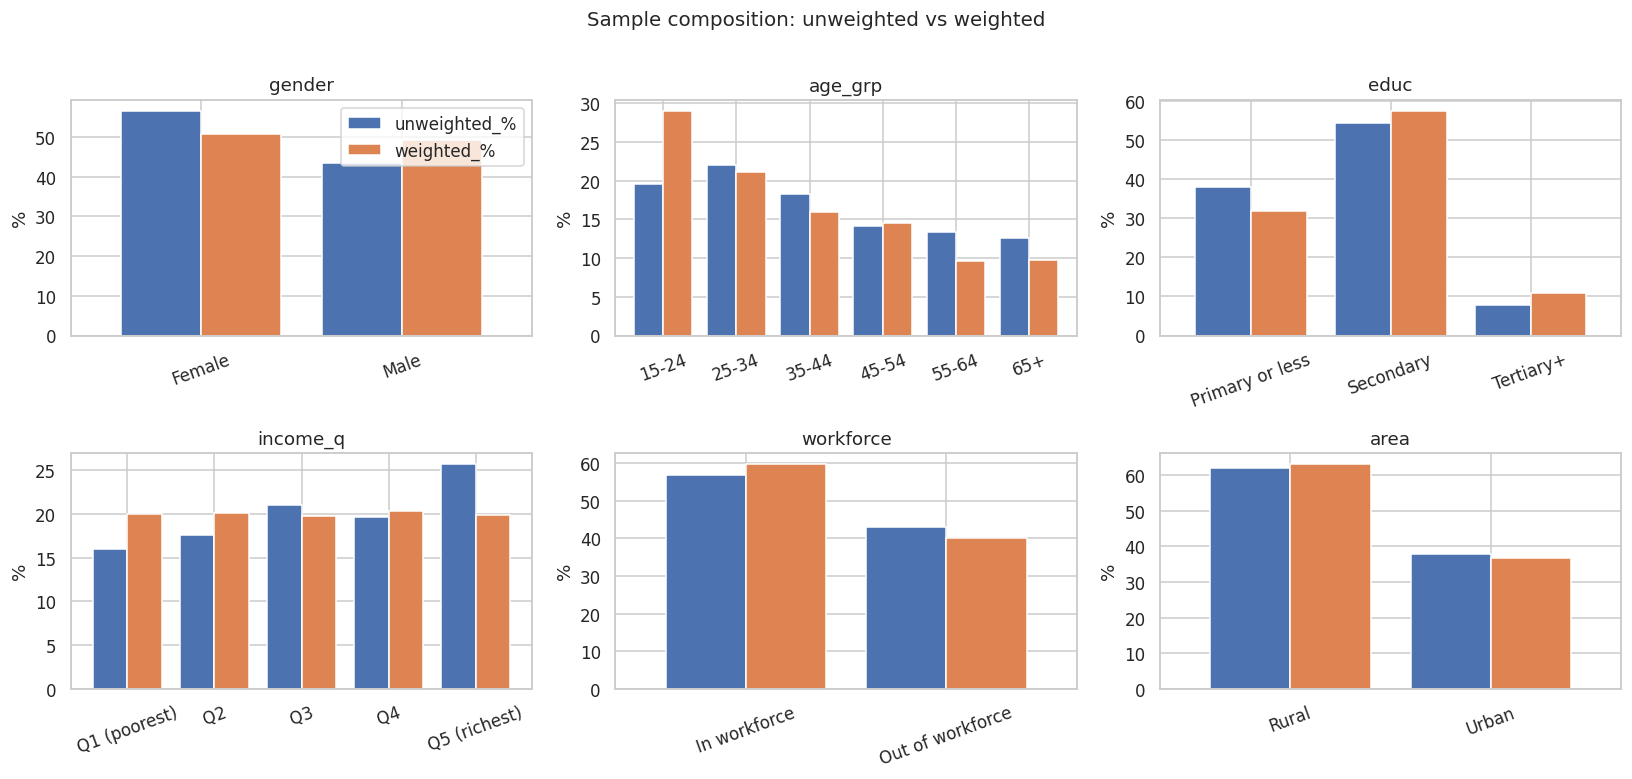

Age (weighted mean): 38.0 | unweighted mean: 41.5 | median: 39


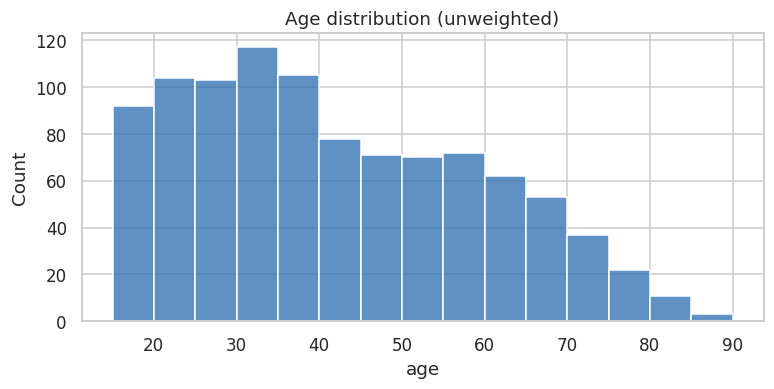

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, g in zip(axes.ravel(), ["gender","age_grp","educ","income_q","workforce","area"]):
    t = comp(lab[g])[["unweighted_%","weighted_%"]]
    t.plot.bar(ax=ax, rot=20, width=.8); ax.set_title(g); ax.set_xlabel(""); ax.set_ylabel("%")
    if ax is not axes[0,0]: ax.get_legend().remove()
plt.suptitle("Sample composition: unweighted vs weighted", y=1.01, fontsize=13); plt.tight_layout(); plt.show()

print("Age (weighted mean): %.1f | unweighted mean: %.1f | median: %.0f" % (np.average(dc.age, weights=w), dc.age.mean(), dc.age.median()))
fig, ax = plt.subplots(figsize=(8,3.4)); sns.histplot(dc.age, bins=range(15,95,5), ax=ax, color="#2b6cb0"); ax.set_title("Age distribution (unweighted)"); plt.show()

## 6. Headline indicators (weighted, 95% CI)

,weighted_pct,ci_low,ci_high,unweighted_pct,n,n_eff
Owns mobile phone,78.0,74.1,81.9,79.8,1000,429
Experienced natural disaster (3y),77.5,73.6,81.5,77.5,1000,429
Has foundational ID,74.1,69.9,78.2,70.7,995,428
Borrowed (any),72.0,67.7,76.2,73.1,1000,429
Used internet (3 months),70.7,66.4,75.0,68.8,1000,429
Smartphone (of all adults),69.0,64.6,73.4,68.8,1000,429
Saved (any),53.6,48.9,58.4,52.0,1000,429
Any account,50.2,45.5,54.9,48.9,1000,429
Any digital payment,40.3,35.7,45.0,38.4,1000,429
Financial institution acct,33.5,29.1,38.0,33.9,1000,429


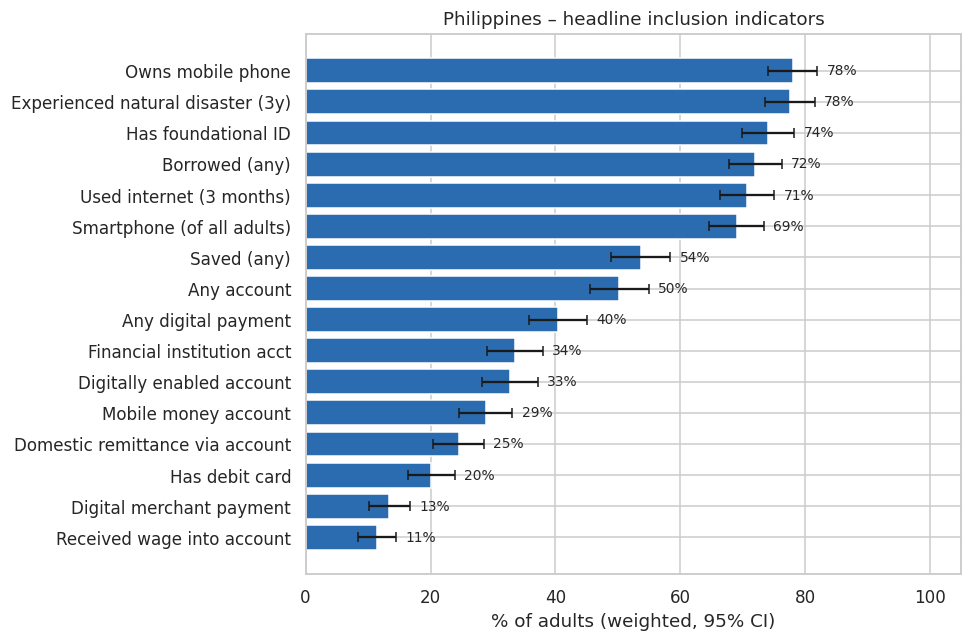

In [12]:
def wprop(x, wt):
    m = x.notna() & wt.notna()
    x, wt = x[m], wt[m]
    if len(x) == 0: return (np.nan,)*4
    p  = np.average(x, weights=wt)
    ne = wt.sum()**2 / (wt**2).sum()
    se = np.sqrt(max(p*(1-p), 0) / ne)
    return p, se, len(x), ne

def summarize(frame, wt):
    rows = {}
    for c in frame.columns:
        p, se, n, ne = wprop(frame[c], wt)
        rows[c] = dict(weighted_pct=100*p, ci_low=100*max(p-1.96*se,0), ci_high=100*min(p+1.96*se,1), unweighted_pct=100*frame[c].mean(), n=n, n_eff=ne)
    return pd.DataFrame(rows).T

head = summarize(ind, w).sort_values("weighted_pct", ascending=False)
display(head.style.format({"weighted_pct":"{:.1f}","ci_low":"{:.1f}","ci_high":"{:.1f}","unweighted_pct":"{:.1f}","n":"{:.0f}","n_eff":"{:.0f}"}))

fig, ax = plt.subplots(figsize=(9, 6))
h = head.iloc[::-1]
ax.barh(h.index, h.weighted_pct, xerr=[h.weighted_pct-h.ci_low, h.ci_high-h.weighted_pct], color="#2b6cb0", capsize=3)
for i, (v, hi) in enumerate(zip(h.weighted_pct, h.ci_high)): ax.text(hi+1.5, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("% of adults (weighted, 95% CI)"); ax.set_title("Philippines – headline inclusion indicators")
plt.tight_layout(); plt.show()

## 7. Who is left behind? Gaps by group

In [13]:
KEY = ["Any account","Financial institution acct","Mobile money account","Digitally enabled account","Any digital payment","Owns mobile phone","Used internet (3 months)","Has foundational ID"]
GROUPS = {"gender":"Gender","age_grp":"Age","educ":"Education","income_q":"Income quintile","area":"Area","workforce":"Workforce"}

def by_group(g, cols=KEY):
    out = {}
    for lv, idx in lab.groupby(g, observed=True).groups.items():
        out[lv] = {c: 100*wprop(ind.loc[idx, c], w.loc[idx])[0] for c in cols}
    return pd.DataFrame(out).T

heat = pd.concat({GROUPS[g]: by_group(g) for g in GROUPS})
display(heat.style.format("{:.0f}").background_gradient(cmap="YlGnBu", vmin=0, vmax=100))

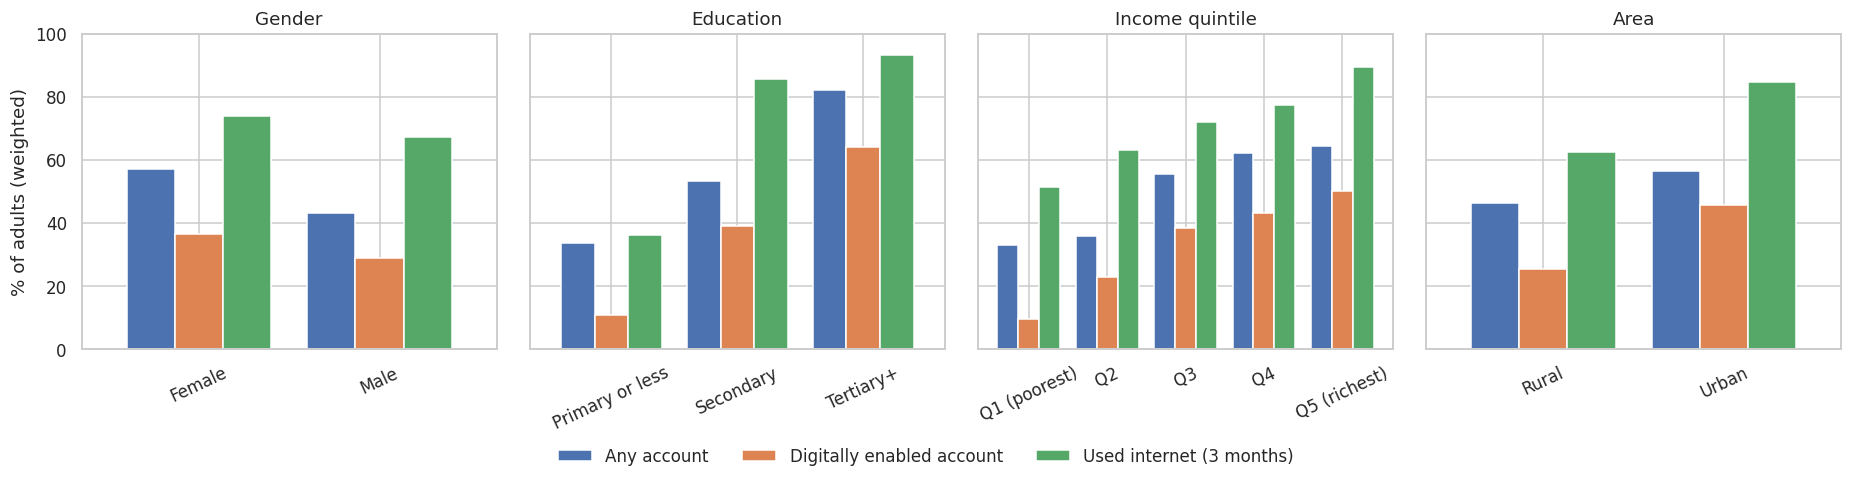

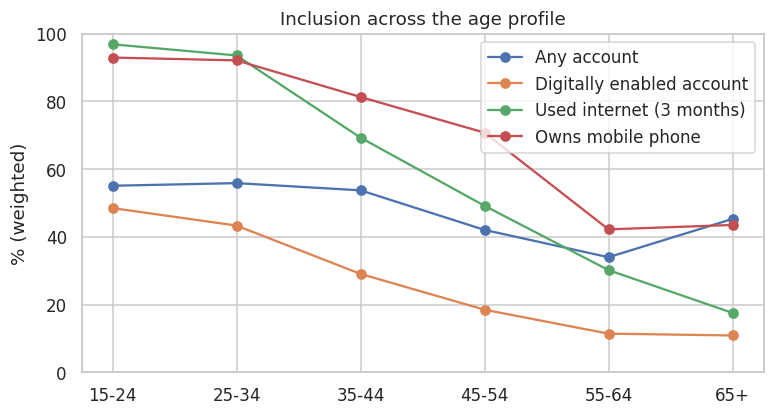

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, g in zip(axes, ["gender","educ","income_q","area"]):
    d_ = by_group(g, ["Any account","Digitally enabled account","Used internet (3 months)"])
    d_.plot.bar(ax=ax, rot=25, width=.8); ax.set_title(GROUPS[g]); ax.set_xlabel(""); ax.set_ylim(0,100)
    hd, lb = ax.get_legend_handles_labels(); ax.get_legend().remove()
axes[0].set_ylabel("% of adults (weighted)")
fig.legend(hd, lb, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
d_ = by_group("age_grp", ["Any account","Digitally enabled account","Used internet (3 months)","Owns mobile phone"])
d_.plot(marker="o", ax=ax); ax.set_ylim(0,100); ax.set_ylabel("% (weighted)"); ax.set_title("Inclusion across the age profile"); plt.show()

In [15]:
# Gender gap in account ownership by income quintile / area - with cell sizes (small cells are noisy!)
def gap_table(by):
    rows = []
    for lv, idx in lab.groupby(by, observed=True).groups.items():
        f = idx.intersection(lab.index[lab.gender=="Female"]); m = idx.intersection(lab.index[lab.gender=="Male"])
        pf, _, nf, _ = wprop(ind.loc[f,"Any account"], w.loc[f]); pm, _, nm, _ = wprop(ind.loc[m,"Any account"], w.loc[m])
        rows.append(dict(group=lv, female_pct=100*pf, male_pct=100*pm, gap_pp=100*(pf-pm), n_female=nf, n_male=nm))
    return pd.DataFrame(rows).set_index("group")
for b in ["income_q","area","educ"]:
    print(f"\nAccount ownership, female vs male, by {b}:"); display(gap_table(b).style.format("{:.1f}", subset=["female_pct","male_pct","gap_pp"]))
print("Gaps based on cells with n < ~50 should be treated as indicative only.")


Account ownership, female vs male, by income_q:


,female_pct,male_pct,gap_pp,n_female,n_male
group,,,,,
Q1 (poorest),44.9,18.9,26.0,96,64
Q2,39.5,31.2,8.3,101,75
Q3,72.6,34.8,37.8,128,82
Q4,68.1,56.4,11.7,116,81
Q5 (richest),63.9,64.9,-1.0,125,132



Account ownership, female vs male, by area:


,female_pct,male_pct,gap_pp,n_female,n_male
group,,,,,
Rural,53.6,38.4,15.2,356,264
Urban,63.9,50.1,13.8,210,170



Account ownership, female vs male, by educ:


,female_pct,male_pct,gap_pp,n_female,n_male
group,,,,,
Primary or less,35.0,32.5,2.5,200,180
Secondary,61.8,43.6,18.1,321,221
Tertiary+,83.4,80.5,2.8,45,33


Gaps based on cells with n < ~50 should be treated as indicative only.


## 8. Digital payments, savings, borrowing

In [16]:
# Sources of saving / borrowing (yes = code 1; base = all who answered)
SAVE = {"Saved at bank/FI":"fin17a","Saved w/ mobile money (of MM users)":"fin17b","Saved in club/with person outside family":"fin17c","Saved for old age (of formal savers)":"fin17f"}
BORR = {"Borrowed from bank/FI":"fin22a","Borrowed from mobile money provider (of MM users)":"fin22a_1","Borrowed from family/friends":"fin22b","Borrowed for health":"fin22d","Borrowed for business":"fin22e","Bought food on credit":"fin22f"}
def tab(d):
    fr = pd.DataFrame({k: yes(v) for k, v in d.items()}); return summarize(fr, w)[["weighted_pct","ci_low","ci_high","n"]]
display(pd.concat({"Saving": tab(SAVE), "Borrowing": tab(BORR)}).style.format({"weighted_pct":"{:.1f}","ci_low":"{:.1f}","ci_high":"{:.1f}","n":"{:.0f}"}))

pay = pd.DataFrame({
    "Wage into account": (dc.receive_wages==1), "Wage in cash only": (dc.receive_wages==2),
    "Gov. transfer into account": (dc.receive_transfers==1), "Gov. transfer in cash only": (dc.receive_transfers==2),
    "Utility paid from account": (dc.pay_utilities==1), "Utility paid cash only": (dc.pay_utilities==2),
    "Domestic remittance via account": (dc.domestic_remittances==1), "Domestic remittance other method": (dc.domestic_remittances==2),
}).astype(float)
display(summarize(pay, w)[["weighted_pct","ci_low","ci_high","n"]].style.format("{:.1f}", subset=["weighted_pct","ci_low","ci_high"]))

,weighted_pct,ci_low,ci_high,n
Wage into account,11.4,8.4,14.4,1000.000000
Wage in cash only,24.3,20.2,28.3,1000.000000
Gov. transfer into account,7.0,4.6,9.5,1000.000000
Gov. transfer in cash only,16.2,12.7,19.7,1000.000000
Utility paid from account,12.2,9.1,15.3,1000.000000
Utility paid cash only,62.5,57.9,67.0,1000.000000
Domestic remittance via account,24.5,20.4,28.6,1000.000000
Domestic remittance other method,22.3,18.4,26.3,1000.000000


## 9. Barriers: no account, no phone, no smartphone
Asked only of the relevant subgroup, so percentages are **of that subgroup**. Note that `fin11*` refers to financial-institution accounts and *excludes* mobile money (see codebook).

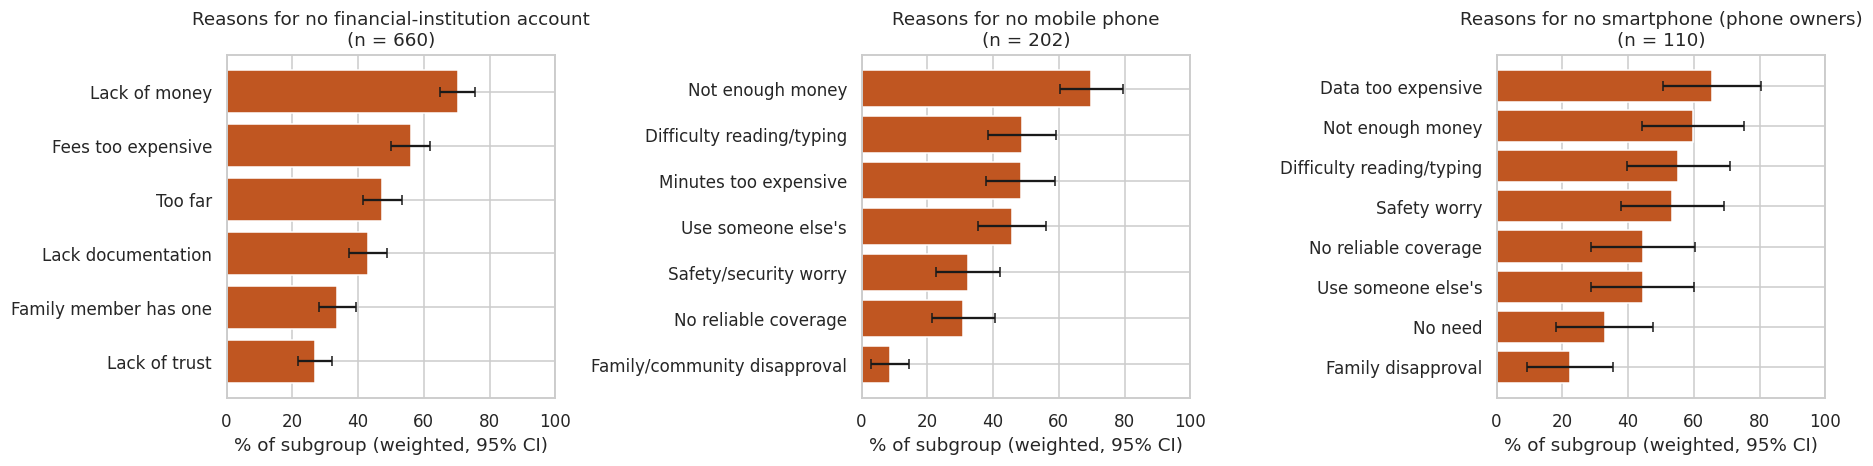

Small base warning: no-phone n = 200 | no-smartphone n = 110


In [17]:
def barrier_chart(items, title, ax):
    fr = pd.DataFrame({k: yes(v) for k, v in items.items()})
    s = summarize(fr, w).sort_values("weighted_pct")
    ax.barh(s.index, s.weighted_pct, xerr=[s.weighted_pct-s.ci_low, s.ci_high-s.weighted_pct], color="#c05621", capsize=3)
    ax.set_title(f"{title}\n(n = {int(s.n.max())})"); ax.set_xlabel("% of subgroup (weighted, 95% CI)"); ax.set_xlim(0,100)

NOACC = {"Lack of money":"fin11d","Family member has one":"fin11e","Too far":"fin11a","Fees too expensive":"fin11b","Lack documentation":"fin11c","Lack of trust":"fin11f"}
NOPHONE = {"Not enough money":"con2a","Minutes too expensive":"con2b","No reliable coverage":"con2c","Difficulty reading/typing":"con2d","Family/community disapproval":"con2e","Safety/security worry":"con2f","Use someone else's":"con2g"}
NOSMART = {"Not enough money":"con31a","Data too expensive":"con31b","No reliable coverage":"con31c","Difficulty reading/typing":"con31d","Family disapproval":"con31e","Safety worry":"con31f","Use someone else's":"con31g","No need":"con31h"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
barrier_chart(NOACC, "Reasons for no financial-institution account", axes[0])
barrier_chart(NOPHONE, "Reasons for no mobile phone", axes[1])
barrier_chart(NOSMART, "Reasons for no smartphone (phone owners)", axes[2])
plt.tight_layout(); plt.show()
print("Small base warning: no-phone n =", int(dc.con2a.notna().sum()), "| no-smartphone n =", int(dc.con31a.notna().sum()))

## 10. Financial resilience and worries

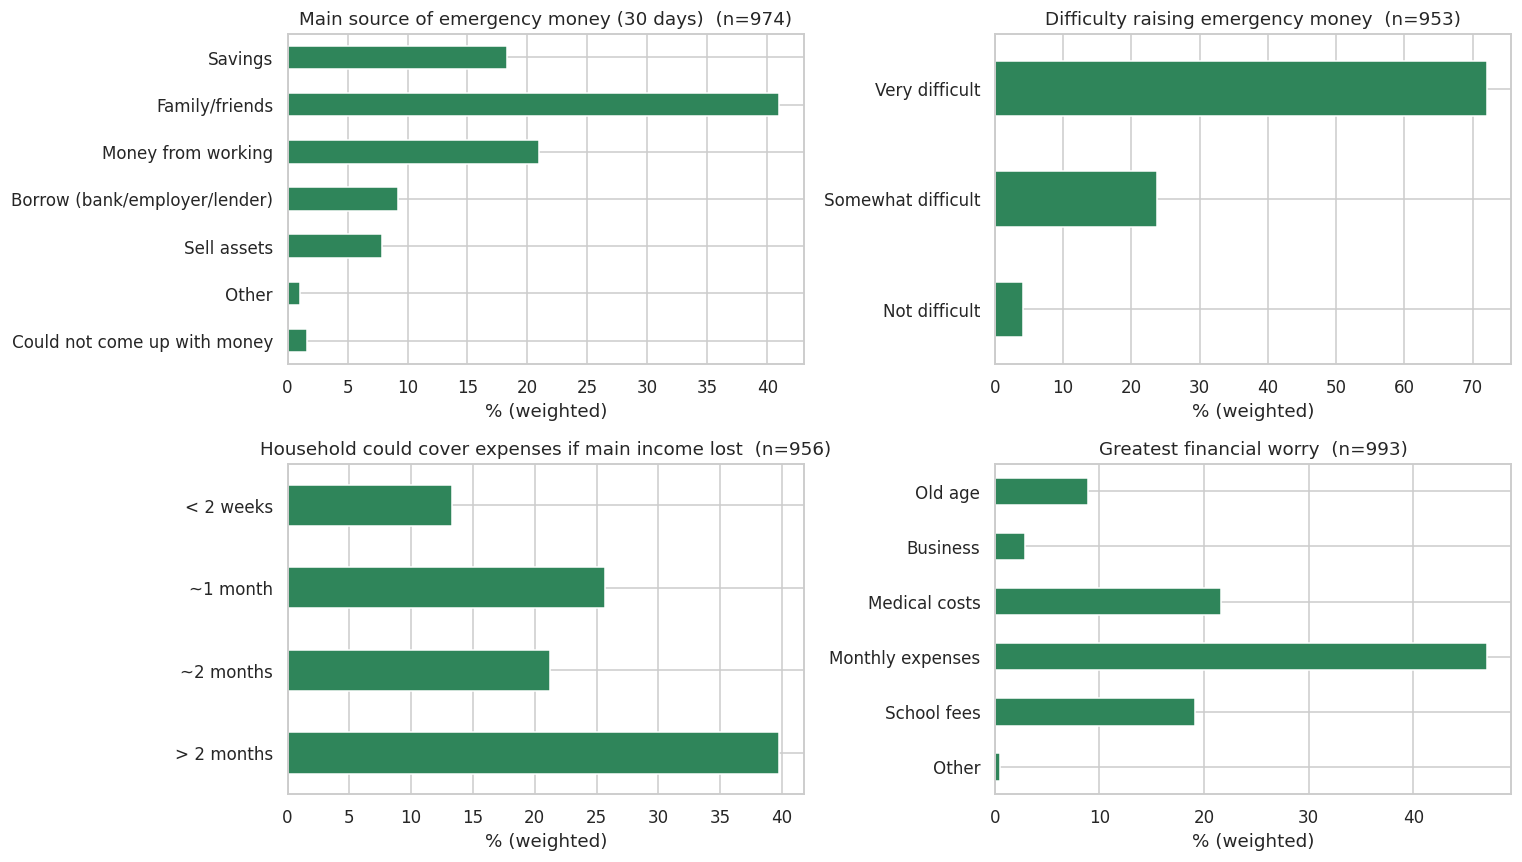

In [18]:
FIN24 = {1:"Savings",2:"Family/friends",3:"Money from working",4:"Borrow (bank/employer/lender)",5:"Sell assets",6:"Other",7:"Could not come up with money"}
FIN45 = {1:"Old age",2:"Business",3:"Medical costs",4:"Monthly expenses",5:"School fees",6:"Other"}
FIN24A= {1:"Very difficult",2:"Somewhat difficult",3:"Not difficult"}
FIN24B= {1:"< 2 weeks",2:"~1 month",3:"~2 months",4:"> 2 months"}

def wdist(col, mapping):
    s = dc[col].map(mapping); m = s.notna()
    t = (w[m].groupby(s[m]).sum() / w[m].sum() * 100).reindex(list(mapping.values())).fillna(0)
    return t, int(m.sum())

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (col, mp, ttl) in zip(axes.ravel(), [("fin24",FIN24,"Main source of emergency money (30 days)"),("fin24a",FIN24A,"Difficulty raising emergency money"),
                                              ("fin24b",FIN24B,"Household could cover expenses if main income lost"),("fin45",FIN45,"Greatest financial worry")]):
    t, n = wdist(col, mp); t.iloc[::-1].plot.barh(ax=ax, color="#2f855a"); ax.set_title(f"{ttl}  (n={n})"); ax.set_xlabel("% (weighted)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [19]:
# Resilience by income quintile: share who could NOT come up with emergency funds, or would face "very difficult"
res = pd.DataFrame({"Could not raise emergency money": (dc.fin24==7).astype(float).where(dc.fin24.notna()),
                    "Very difficult (of those who could)": (dc.fin24a==1).astype(float).where(dc.fin24a.notna()),
                    "Household lasts < 2 weeks": (dc.fin24b==1).astype(float).where(dc.fin24b.notna())})
out = {}
for lv, idx in lab.groupby("income_q", observed=True).groups.items():
    out[lv] = {c: 100*wprop(res.loc[idx,c], w.loc[idx])[0] for c in res}
display(pd.DataFrame(out).T.style.format("{:.0f}").background_gradient(cmap="OrRd"))

,Could not raise emergency money,Very difficult (of those who could),Household lasts < 2 weeks
Q1 (poorest),2,82,12
Q2,3,86,8
Q3,2,75,10
Q4,1,70,16
Q5 (richest),0,49,20


## 11. Connectivity and digital behaviours

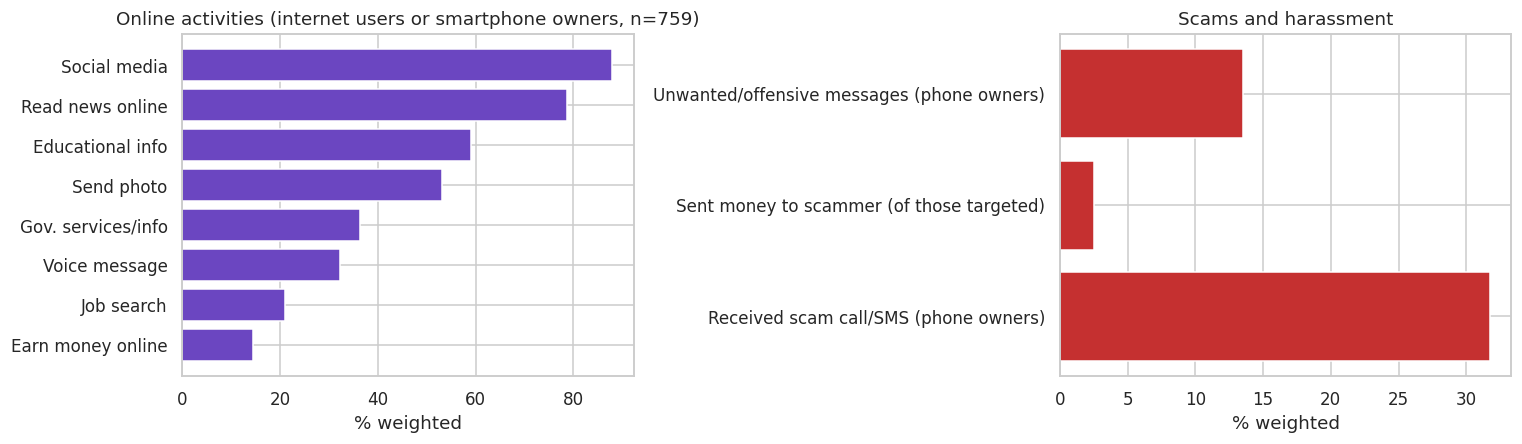

,weighted_pct,ci_low,ci_high,n
Received scam call/SMS (phone owners),31.7,26.8,36.7,798.000000
Sent money to scammer (of those targeted),2.5,0.0,5.4,253.000000
Unwanted/offensive messages (phone owners),13.5,9.9,17.2,797.000000


In [20]:
ACT = {"Social media":"con30c","Voice message":"con30a","Send photo":"con30b","Read news online":"con30d","Educational info":"con30e","Earn money online":"con30f","Gov. services/info":"con30g","Job search":"con30h"}
act = summarize(pd.DataFrame({k: yes(v) for k,v in ACT.items()}), w).sort_values("weighted_pct")
risk = summarize(pd.DataFrame({"Received scam call/SMS (phone owners)":yes("con21"),"Sent money to scammer (of those targeted)":yes("con22"),"Unwanted/offensive messages (phone owners)":yes("con23")}), w)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].barh(act.index, act.weighted_pct, color="#6b46c1"); ax[0].set_title(f"Online activities (internet users or smartphone owners, n={int(act.n.max())})"); ax[0].set_xlabel("% weighted")
ax[1].barh(risk.index, risk.weighted_pct, color="#c53030"); ax[1].set_title("Scams and harassment"); ax[1].set_xlabel("% weighted")
plt.tight_layout(); plt.show()
display(risk[["weighted_pct","ci_low","ci_high","n"]].style.format("{:.1f}", subset=["weighted_pct","ci_low","ci_high"]))

## 12. Consistency checks against the codebook

In [21]:
checks = []
def chk(name, cond, detail=""): checks.append(dict(check=name, violations=int((~cond).sum()), detail=detail))

chk("account == account_fin OR account_mob", df.account == ((df.account_fin==1)|(df.account_mob==1)).astype(int))
chk("dig_account=1 implies account=1", ~((df.dig_account==1) & (df.account==0)))
chk("fin11* (no-account reasons) asked only of account_fin==0", ~(df.fin11a.notna() & (df.account_fin==1)))
chk("fin3 (card/phone use) asked only of FI-account owners", ~(df.fin3.notna() & (df.account_fin==0)))
chk("con9 (phone type) asked only of phone owners", ~(df.con9.notna() & (df.con1!=1)))
chk("con2* (no-phone reasons) asked only of non-owners", ~(df.con2a.notna() & (df.con1==1)))
chk("internet_use=1 <=> con24==1 or con25==1", (df.internet_use==1) == ((df.con24==1)|(df.con25==1)))
chk("fin17b (saved w/ mobile money) asked only of MM owners", ~(df.fin17b.notna() & (df.account_mob==0)), "codebook says MM accounts only")
chk("fin22a_1 (borrowed from MM provider) asked only of MM owners", ~(df.fin22a_1.notna() & (df.account_mob==0)), "codebook says MM accounts only")
chk("fin35 (unexpected wage fee) only if wage received into account", ~(df.fin35.notna() & (df.receive_wages!=1)))
chk("age within 15-100", df.age.between(15,100))
chk("weights positive", df.wgt > 0)
cr = pd.DataFrame(checks); display(cr)

print("\nCross-tab: fin17b answered vs account_mob (codebook says fin17b is asked only of mobile-money owners)")
display(pd.crosstab(df.fin17b.notna().rename("fin17b answered"), df.account_mob.rename("account_mob")))
print("Cross-tab: internet_use vs con24 (1=yes,2=no,3=undocumented)")
display(pd.crosstab(df.internet_use, df.con24))

,check,violations,detail
0,account == account_fin OR account_mob,0,
1,dig_account=1 implies account=1,0,
2,fin11* (no-account reasons) asked only of acco...,0,
3,fin3 (card/phone use) asked only of FI-account...,0,
4,con9 (phone type) asked only of phone owners,0,
5,con2* (no-phone reasons) asked only of non-owners,0,
6,internet_use=1 <=> con24==1 or con25==1,0,
7,fin17b (saved w/ mobile money) asked only of M...,115,codebook says MM accounts only
8,fin22a_1 (borrowed from MM provider) asked onl...,115,codebook says MM accounts only
9,fin35 (unexpected wage fee) only if wage recei...,0,



Cross-tab: fin17b answered vs account_mob (codebook says fin17b is asked only of mobile-money owners)


account_mob,0,1
fin17b answered,,
False,627,7
True,115,251


Cross-tab: internet_use vs con24 (1=yes,2=no,3=undocumented)


con24,1,2,3
internet_use,,,
0,0,311,1
1,653,35,0


## 13. Relationships between key indicators
Plain (unweighted) phi/Pearson correlations of 0/1 indicators. This is for orientation only; use weighted models for inference.

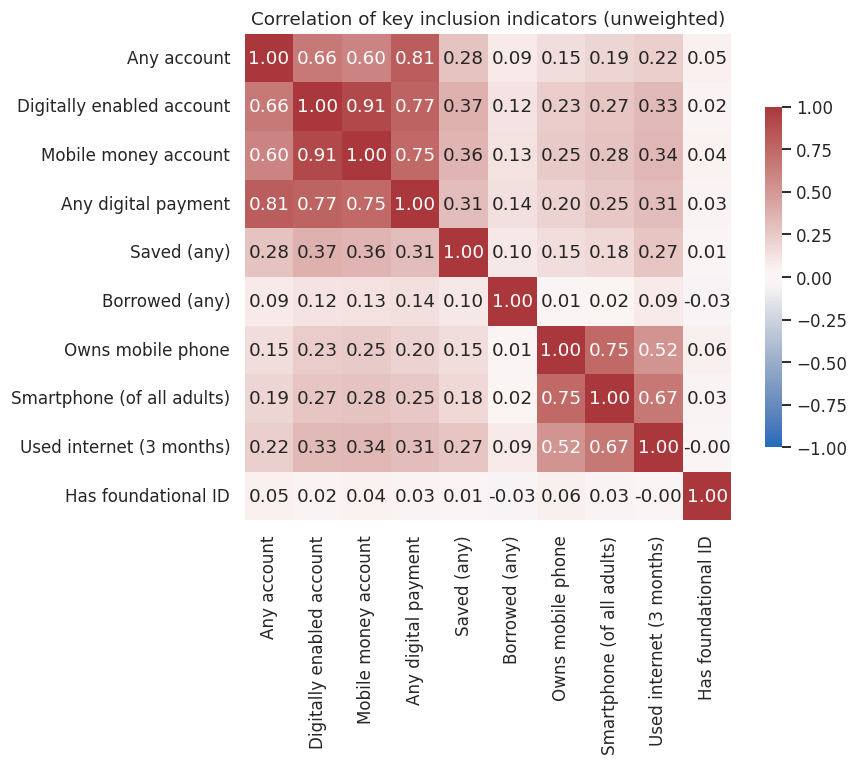

,age,education (1-3),income quintile,female,urban
Any account,-0.06,0.24,0.20,0.06,0.06
Digitally enabled account,-0.27,0.29,0.27,0.04,0.18
Used internet (3 months),-0.57,0.43,0.25,0.06,0.18


In [22]:
cols = ["Any account","Digitally enabled account","Mobile money account","Any digital payment","Saved (any)","Borrowed (any)","Owns mobile phone","Smartphone (of all adults)","Used internet (3 months)","Has foundational ID"]
cm = ind[cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink":.7}, ax=ax)
ax.set_title("Correlation of key inclusion indicators (unweighted)"); plt.tight_layout(); plt.show()

# Add demographics as numerics
num = pd.concat([ind[["Any account","Digitally enabled account","Used internet (3 months)"]],
                 dc[["age","educ","inc_q"]].rename(columns={"educ":"education (1-3)","inc_q":"income quintile"}),
                 (dc.female==1).astype(int).rename("female"), (dc.urbanicity==2).astype(int).rename("urban")], axis=1)
display(num.corr().loc[["Any account","Digitally enabled account","Used internet (3 months)"], ["age","education (1-3)","income quintile","female","urban"]].style.format("{:.2f}").background_gradient(cmap="vlag", vmin=-.6, vmax=.6))